# Exploratory data analysis

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Find the project root (the folder containing src/churn), whatever the working directory is.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "churn").exists())
sys.path.insert(0, str(ROOT / "src"))
from churn.data import ID_COL, TARGET, clean, load_raw  # noqa: E402

RAW = ROOT / "data" / "raw" / "telco.csv"
raw = load_raw(RAW)
df = clean(raw)
print(df.shape)

(7043, 20)


## First look

In [2]:
raw.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [3]:
raw.isna().sum().sum(), (raw == " ").sum().sum()

(np.int64(0), np.int64(11))

## Target Balance

In [4]:
df[TARGET].value_counts(normalize=True).round(3)

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

## Numeric Features

In [5]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(1)

,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7043.0
mean,32.4,64.8,2279.7
std,24.6,30.1,2266.8
min,0.0,18.2,0.0
25%,9.0,35.5,398.6
50%,29.0,70.4,1394.6
75%,55.0,89.8,3786.6
max,72.0,118.8,8684.8


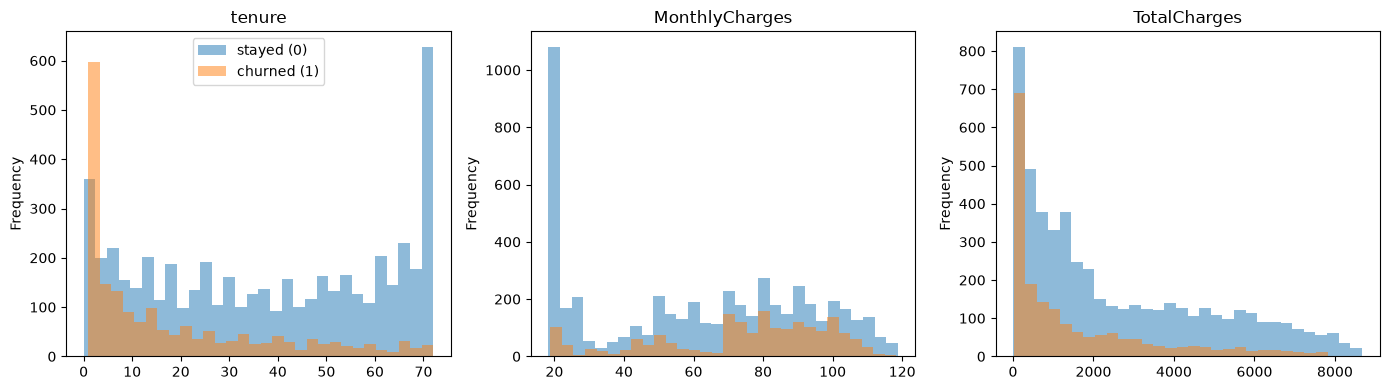

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    df.groupby(TARGET)[col].plot.hist(ax=ax, bins=30, alpha=0.5, legend=False)
    ax.set_title(col)
axes[0].legend(["stayed (0)", "churned (1)"])
plt.tight_layout()
plt.show()

Churners tend to have short tenure and high monthly charges. The tenure histogram is the key one: most churn happens early.

In [7]:
df.groupby(pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72]), observed=True)[TARGET].agg(
    ["mean", "size"]
).rename(columns={"mean": "churn_rate", "size": "customers"}).round(3)

,churn_rate,customers
tenure,,
"(-1, 6]",0.529,1481
"(6, 12]",0.359,705
"(12, 24]",0.287,1024
"(24, 48]",0.204,1594
"(48, 72]",0.095,2239


## Categorical Features

In [8]:
categorical = [c for c in df.columns if df[c].dtype == "object" or str(df[c].dtype) == "str"]
categorical = [c for c in categorical if c not in ("TotalCharges",)]

rates = {
    col: df.groupby(col)[TARGET].mean().round(3).sort_values(ascending=False)
    for col in categorical
}
for col, series in rates.items():
    print(f"\n{col}\n{series.to_string()}")


gender
gender
Female    0.269
Male      0.262

Partner
Partner
No     0.330
Yes    0.197

Dependents
Dependents
No     0.313
Yes    0.155

PhoneService
PhoneService
Yes    0.267
No     0.249

MultipleLines
MultipleLines
Yes                 0.286
No                  0.250
No phone service    0.249

InternetService
InternetService
Fiber optic    0.419
DSL            0.190
No             0.074

OnlineSecurity
OnlineSecurity
No                     0.418
Yes                    0.146
No internet service    0.074

OnlineBackup
OnlineBackup
No                     0.399
Yes                    0.215
No internet service    0.074

DeviceProtection
DeviceProtection
No                     0.391
Yes                    0.225
No internet service    0.074

TechSupport
TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074

StreamingTV
StreamingTV
No                     0.335
Yes                    0.301
No internet service    0.074

StreamingMovies
StreamingM

Contract type and internet service stand out. Month-to-month contracts churn most. Fibre optic customers churn more than DSL customers. Services like tech support and online security look protective.

## Data consistency checks

In [9]:
expected = df["tenure"] * df["MonthlyCharges"]
gap = (df["TotalCharges"] - expected).abs()
print("median absolute gap:", round(gap.median(), 2))
print("rows with gap over 50%:", int((gap > 0.5 * expected.clip(lower=1)).sum()))

median absolute gap: 28.6
rows with gap over 50%: 2


In [10]:
print("duplicate customer IDs:", raw[ID_COL].duplicated().sum())
print("duplicate rows:", raw.duplicated().sum())

duplicate customer IDs: 0
duplicate rows: 0


In [11]:
list(df.columns)

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

## Correlations among numeric features

In [12]:
df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", TARGET]].corr().round(2)

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
tenure,1.00,0.25,0.83,0.02,-0.35
MonthlyCharges,0.25,1.00,0.65,0.22,0.19
TotalCharges,0.83,0.65,1.00,0.10,-0.20
SeniorCitizen,0.02,0.22,0.10,1.00,0.15
Churn,-0.35,0.19,-0.20,0.15,1.00


## Visualizations

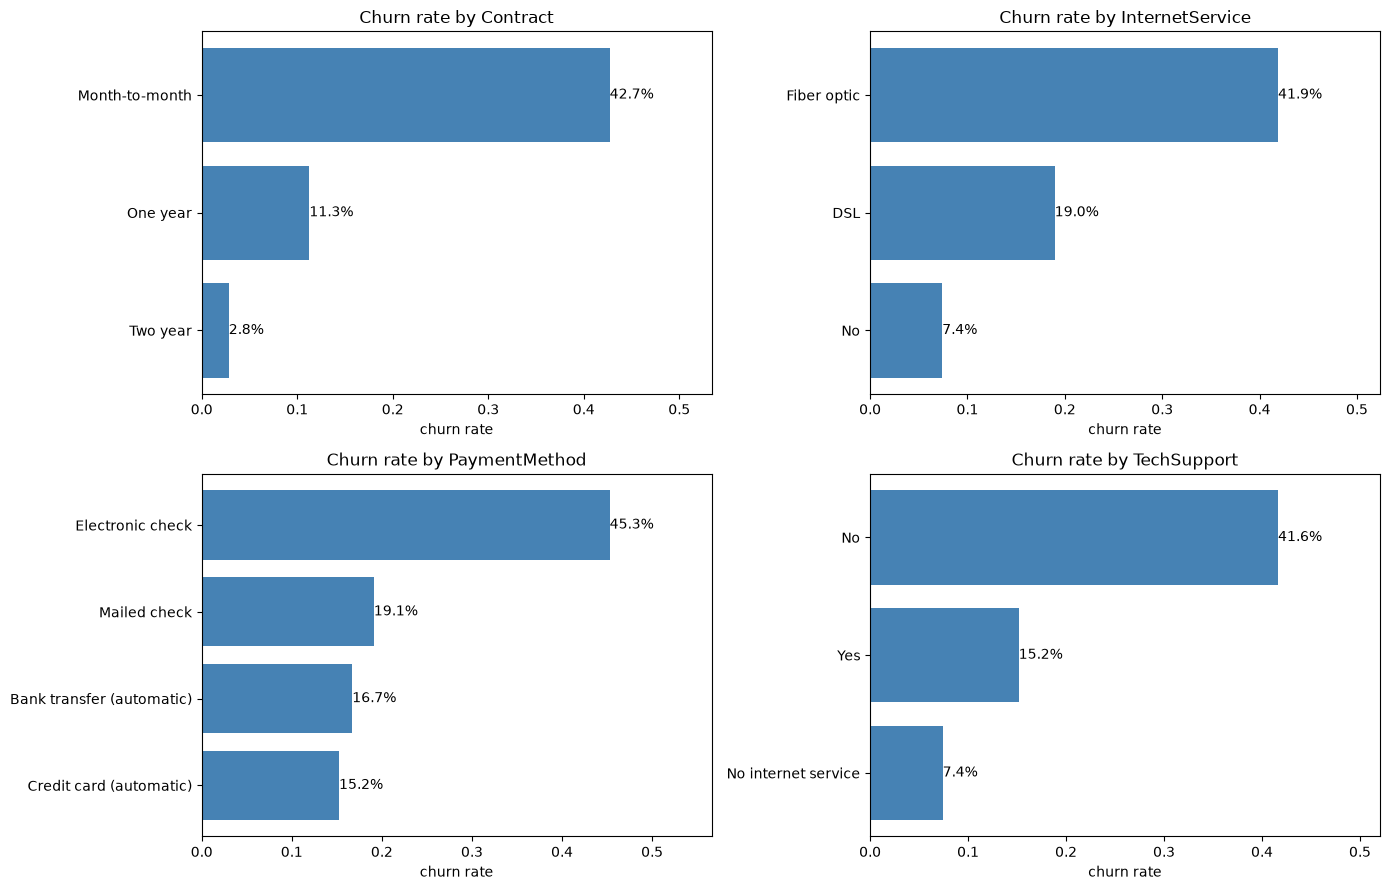

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

features = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), features):
    rate = df.groupby(col)[TARGET].mean().sort_values()
    bars = ax.barh(rate.index.astype(str), rate.values, color="steelblue")
    ax.bar_label(bars, fmt="%.1f%%", labels=[f"{v*100:.1f}%" for v in rate.values])
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlim(0, rate.max() * 1.25)
    ax.set_xlabel("churn rate")
plt.tight_layout()
plt.show()

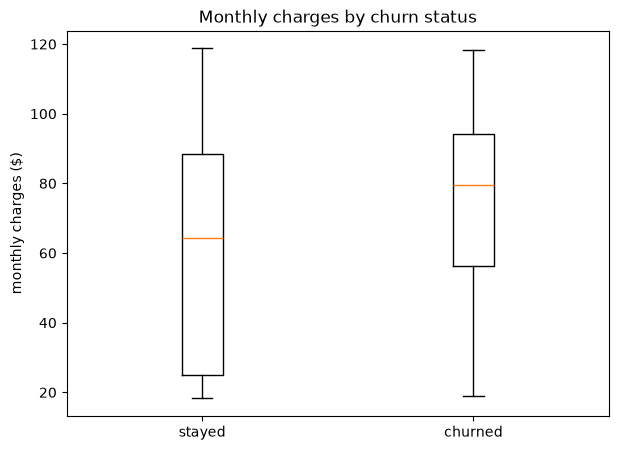

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
data = [df.loc[df[TARGET] == v, "MonthlyCharges"] for v in (0, 1)]
ax.boxplot(data, showfliers=False)
ax.set_xticks([1, 2], ["stayed", "churned"])
ax.set_ylabel("monthly charges ($)")
ax.set_title("Monthly charges by churn status")
plt.show()

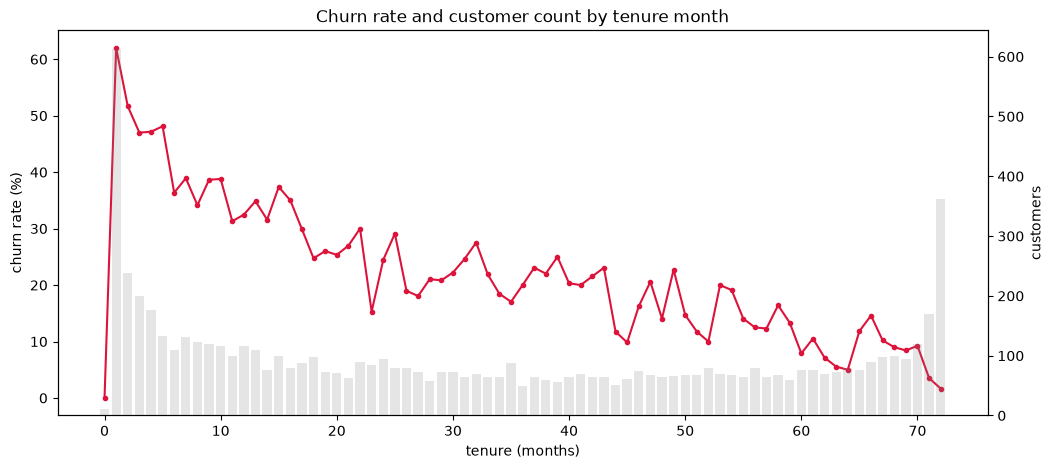

In [15]:
by_month = df.groupby("tenure")[TARGET].agg(["mean", "size"])
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(by_month.index, by_month["mean"] * 100, marker="o", ms=3, color="crimson")
ax1.set_xlabel("tenure (months)")
ax1.set_ylabel("churn rate (%)")
ax2 = ax1.twinx()
ax2.bar(by_month.index, by_month["size"], alpha=0.2, color="grey")
ax2.set_ylabel("customers")
ax1.set_title("Churn rate and customer count by tenure month")
plt.show()

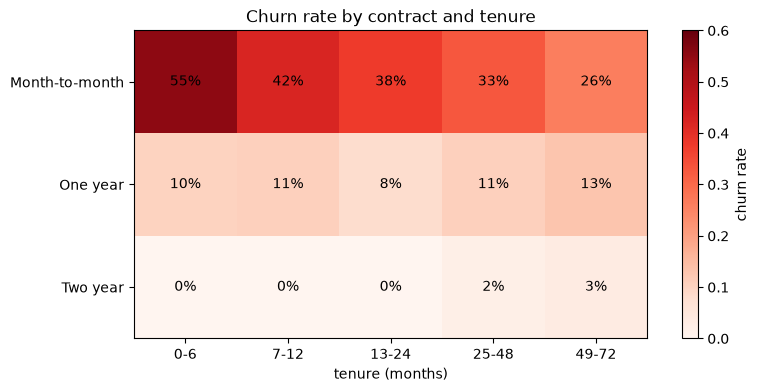

In [16]:
bands = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
               labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
pivot = df.pivot_table(index="Contract", columns=bands, values=TARGET, aggfunc="mean", observed=False)
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(pivot.values, cmap="Reds", vmin=0, vmax=0.6)
ax.set_xticks(range(pivot.shape[1]), labels=pivot.columns.astype(str))
ax.set_yticks(range(pivot.shape[0]), labels=pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]*100:.0f}%", ha="center", va="center")
ax.set_xlabel("tenure (months)")
ax.set_title("Churn rate by contract and tenure")
fig.colorbar(im, ax=ax, label="churn rate")
plt.show()

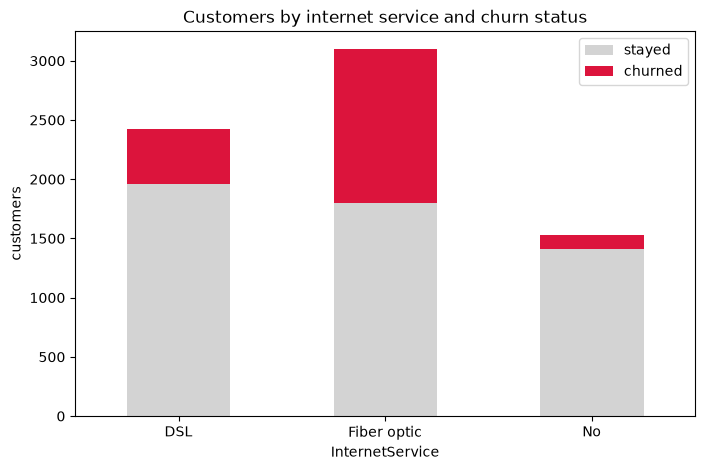

In [17]:
counts = pd.crosstab(df["InternetService"], df[TARGET])
counts.columns = ["stayed", "churned"]
fig, ax = plt.subplots(figsize=(8, 5))
counts.plot(kind="bar", stacked=True, ax=ax, color=["lightgrey", "crimson"], rot=0)
ax.set_ylabel("customers")
ax.set_title("Customers by internet service and churn status")
plt.show()

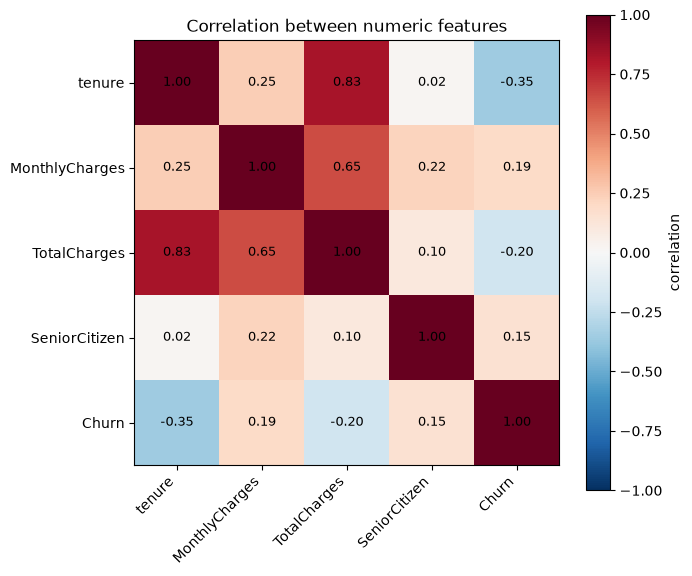

In [18]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", TARGET]]
corr = num.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), labels=corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), labels=corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="correlation")
ax.set_title("Correlation between numeric features")
plt.tight_layout()
plt.show()